In [1]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
from astroquery.mast import Observations
import pandas as pd

/Users/sarkie/Development/jwst-research/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [3]:
observations = Observations.query_criteria(
    proposal_id = 2733
)

print("Observation found: ", len(observations))

Observation found:  12


In [4]:
df = pd.DataFrame(
    {
        col: observations[col]
        for col in observations.columns
    }
)
columns = [
    c for c in [
        "obs_collection",
        "obs_id",
        "target_name",
        "instrument_name",
        "filters",
        "calib_level",
        "dataRights"
    ]
    if c in df.columns
]

display(df[columns].head(20))

,obs_collection,obs_id,target_name,instrument_name,filters,calib_level,dataRights
0,OPO,STSCI_PR_2022-059,Southern Ring Nebula | NGC 3132,NaN,NaN,3,PUBLIC
1,OPO,STSCI_PR_2022-033,NGC 3132 | Southern Ring Nebula | Eight-Burst ...,NaN,NaN,3,PUBLIC
2,JWST,jw02733-o002_t001_miri_f1130w,NGC-3132,MIRI/IMAGE,F1130W,3,PUBLIC
3,JWST,jw02733-o002_t001_miri_f770w,NGC-3132,MIRI/IMAGE,F770W,3,PUBLIC
4,JWST,jw02733-o002_t001_miri_f1800w,NGC-3132,MIRI/IMAGE,F1800W,3,PUBLIC
5,JWST,jw02733-o002_t001_miri_f1280w,NGC-3132,MIRI/IMAGE,F1280W,3,PUBLIC
6,JWST,jw02733-o001_t001_nircam_clear-f187n,NGC-3132,NIRCAM/IMAGE,F187N,3,PUBLIC
7,JWST,jw02733-o001_t001_nircam_clear-f090w,NGC-3132,NIRCAM/IMAGE,F090W,3,PUBLIC
8,JWST,jw02733-o001_t001_nircam_clear-f356w,NGC-3132,NIRCAM/IMAGE,F356W,3,PUBLIC
9,JWST,jw02733-o001_t001_nircam_clear-f212n,NGC-3132,NIRCAM/IMAGE,F212N,3,PUBLIC


In [5]:
products = Observations.get_product_list(observations)

product_df = products.to_pandas()

print("Total files found:", len(product_df))

display(product_df.head(10))

Total files found: 2890


,obsID,obs_collection,dataproduct_type,obs_id,description,type,dataURI,productType,productGroupDescription,productSubGroupDescription,productDocumentationURL,project,prvversion,proposal_id,productFilename,size,parent_obsid,dataRights,calib_level,filters
0,87599183,JWST,image,jw02733002002_02107_00006_mirimage,source/target (L3) : association generator,S,mast:JWST/product/jw02733-o002_20260726t151748...,INFO,NaN,ASN,NaN,CALJWST,2.0.1,2733,jw02733-o002_20260726t151748_image2_00003_asn....,1815,87602456,PUBLIC,2,F1800W
1,87599183,JWST,image,jw02733002002_02107_00006_mirimage,source/target (L3) : association pool,S,mast:JWST/product/jw02733_20260726t151748_pool...,INFO,NaN,POOL,NaN,CALJWST,2.0.1,2733,jw02733_20260726t151748_pool.csv,75729,87602456,PUBLIC,2,F1800W
2,87599183,JWST,image,jw02733002002_02107_00006_mirimage,Preview-Full,S,mast:JWST/product/jw02733002002_02107_00006_mi...,PREVIEW,NaN,NaN,NaN,CALJWST,NaN,2733,jw02733002002_02107_00006_mirimage_uncal.jpg,185213,87602456,PUBLIC,1,F1800W
3,87599183,JWST,image,jw02733002002_02107_00006_mirimage,Preview-Full,S,mast:JWST/product/jw02733002002_02107_00006_mi...,PREVIEW,NaN,NaN,NaN,CALJWST,2.0.1,2733,jw02733002002_02107_00006_mirimage_cal.jpg,102691,87602456,PUBLIC,2,F1800W
4,87599183,JWST,image,jw02733002002_02107_00006_mirimage,Preview-Full,S,mast:JWST/product/jw02733002002_02107_00006_mi...,PREVIEW,NaN,NaN,NaN,CALJWST,2.0.1,2733,jw02733002002_02107_00006_mirimage_i2d.jpg,39513,87602456,PUBLIC,2,F1800W
5,87599183,JWST,image,jw02733002002_02107_00006_mirimage,Preview-Full,S,mast:JWST/product/jw02733002002_02107_00006_mi...,PREVIEW,NaN,NaN,NaN,CALJWST,2.0.1,2733,jw02733002002_02107_00006_mirimage_o002_crf.jpg,154333,87602456,PUBLIC,2,F1800W
6,87599183,JWST,image,jw02733002002_02107_00006_mirimage,Preview-Full,S,mast:JWST/product/jw02733002002_02107_00006_mi...,PREVIEW,NaN,NaN,NaN,CALJWST,2.0.1,2733,jw02733002002_02107_00006_mirimage_rate.jpg,127163,87602456,PUBLIC,2,F1800W
7,87599183,JWST,image,jw02733002002_02107_00006_mirimage,Preview-Full,S,mast:JWST/product/jw02733002002_02107_00006_mi...,PREVIEW,NaN,NaN,NaN,CALJWST,2.0.1,2733,jw02733002002_02107_00006_mirimage_rateints.jpg,128638,87602456,PUBLIC,2,F1800W
8,87599183,JWST,image,jw02733002002_02107_00006_mirimage,exposure (L2c): 2D Calibrated data averaged ov...,S,mast:JWST/product/jw02733002002_02107_00006_mi...,SCIENCE,NaN,ANNNN_CRF,NaN,CALJWST,2.0.1,2733,jw02733002002_02107_00006_mirimage_o002_crf.fits,29767680,87602456,PUBLIC,2,F1800W
9,87599183,JWST,image,jw02733002002_02107_00006_mirimage,exposure (L2b): 2D calibrated exposure average...,S,mast:JWST/product/jw02733002002_02107_00006_mi...,SCIENCE,NaN,CAL,NaN,CALJWST,2.0.1,2733,jw02733002002_02107_00006_mirimage_cal.fits,29721600,87602456,PUBLIC,2,F1800W


In [6]:
# Find calibrated image products
images = product_df[
    product_df["productFilename"].str.endswith(
        ("i2d.fits", "i2d.jpg"),
        na=False
    )
]

print("Image products found:", len(images))


Image products found: 388


In [7]:
display(
    images[
        [
            "productFilename",
            "productSubGroupDescription",
            "calib_level",
            "filters",
            "dataRights",
            "size"
        ]
    ].head(15)
)

,productFilename,productSubGroupDescription,calib_level,filters,dataRights,size
4,jw02733002002_02107_00006_mirimage_i2d.jpg,NaN,2,F1800W,PUBLIC,39513
10,jw02733002002_02107_00006_mirimage_i2d.fits,I2D,2,F1800W,PUBLIC,29476800
19,jw02733001001_02103_00008_nrcb4_i2d.jpg,NaN,2,F187N,PUBLIC,260581
26,jw02733001001_02103_00008_nrcb4_i2d.fits,I2D,2,F187N,PUBLIC,119044800
35,jw02733001001_02101_00007_nrcb2_i2d.jpg,NaN,2,F212N,PUBLIC,565341
42,jw02733001001_02101_00007_nrcb2_i2d.fits,I2D,2,F212N,PUBLIC,118702080
51,jw02733001001_02103_00006_nrcb4_i2d.jpg,NaN,2,F187N,PUBLIC,377039
58,jw02733001001_02103_00006_nrcb4_i2d.fits,I2D,2,F187N,PUBLIC,119044800
67,jw02733001001_02103_00005_nrcblong_i2d.jpg,NaN,2,F444W;F470N,PUBLIC,270714
74,jw02733001001_02103_00005_nrcblong_i2d.fits,I2D,2,F444W;F470N,PUBLIC,120254400


In [8]:
selected_images = images[
    images["productFilename"].str.endswith(".fits", na=False)
    & (images["filters"] == "F187N")
    & (images["productSubGroupDescription"] == "I2D")
    & (images["dataRights"] == "PUBLIC")
]

display(
    selected_images[
        ["productFilename", "filters", "calib_level", "size"]
    ].head(10)
)

,productFilename,filters,calib_level,size
26,jw02733001001_02103_00008_nrcb4_i2d.fits,F187N,2,119044800
58,jw02733001001_02103_00006_nrcb4_i2d.fits,F187N,2,119044800
90,jw02733001001_02103_00002_nrcb3_i2d.fits,F187N,2,118702080
106,jw02733001001_02103_00004_nrcb2_i2d.fits,F187N,2,118702080
202,jw02733001001_02103_00005_nrcb1_i2d.fits,F187N,2,118520640
484,jw02733001001_02103_00006_nrcb3_i2d.fits,F187N,2,118702080
596,jw02733001001_02103_00003_nrcb2_i2d.fits,F187N,2,118702080
612,jw02733001001_02103_00007_nrcb4_i2d.fits,F187N,2,119044800
644,jw02733001001_02103_00005_nrcb4_i2d.fits,F187N,2,119044800
660,jw02733001001_02103_00004_nrcb3_i2d.fits,F187N,2,118702080


In [9]:
filename = selected_images.iloc[0]["productFilename"]

print("Selected Filename: ", filename)

Selected Filename:  jw02733001001_02103_00008_nrcb4_i2d.fits


In [10]:
product_row = products[
    products["productFilename"] == filename
]

manifest = Observations.download_products(
    product_row,
    download_dir = "./jwst_data"
)

display(manifest)

Local Path,Status,Message,URL
str102,str8,object,object
./jwst_data/mastDownload/JWST/jw02733001001_02103_00008_nrcb4/jw02733001001_02103_00008_nrcb4_i2d.fits,COMPLETE,None,None


In [11]:
from pathlib import Path
from astropy.io import fits

In [12]:
fits_files = list(Path("./jwst_data").rglob("*.fits"))

print("FITS files found:", len(fits_files))

FITS files found: 1


In [13]:
for file in fits_files[:5]:
    print(file)

jwst_data/mastDownload/JWST/jw02733001001_02103_00008_nrcb4/jw02733001001_02103_00008_nrcb4_i2d.fits


In [14]:
file_path = fits_files[0]

with fits.open(file_path) as hdul:
    hdul.info()

Filename: jwst_data/mastDownload/JWST/jw02733001001_02103_00008_nrcb4/jw02733001001_02103_00008_nrcb4_i2d.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     275   ()      
  1  SCI           1 ImageHDU        75   (2058, 2064)   float32   
  2  ERR           1 ImageHDU        10   (2058, 2064)   float32   
  3  CON           1 ImageHDU        10   (2058, 2064, 1)   int32   
  4  WHT           1 ImageHDU         9   (2058, 2064)   float32   
  5  VAR_POISSON    1 ImageHDU         9   (2058, 2064)   float32   
  6  VAR_RNOISE    1 ImageHDU         9   (2058, 2064)   float32   
  7  VAR_FLAT      1 ImageHDU         9   (2058, 2064)   float32   
  8  ASDF          1 BinTableHDU     11   1R x 1C   [51735B]   


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

Matplotlib is building the font cache; this may take a moment.


In [16]:
with fits.open(file_path) as hdul:
    science = hdul["SCI"].data.copy()

    header = hdul["SCI"].header
    units = header.get("BUNIT", "Not Specified")

print("Image shape:", science.shape)
print("Pixel units:", units)
print("Minimum:", np.nanmin(science))
print("Maximum:", np.nanmax(science))
print("Median:", np.nanmedian(science))
print("NaN pixels:", np.isnan(science).sum())

Image shape: (2064, 2058)
Pixel units: MJy/sr
Minimum: -87.22454
Maximum: 35046.04
Median: 0.69330823
NaN pixels: 78403


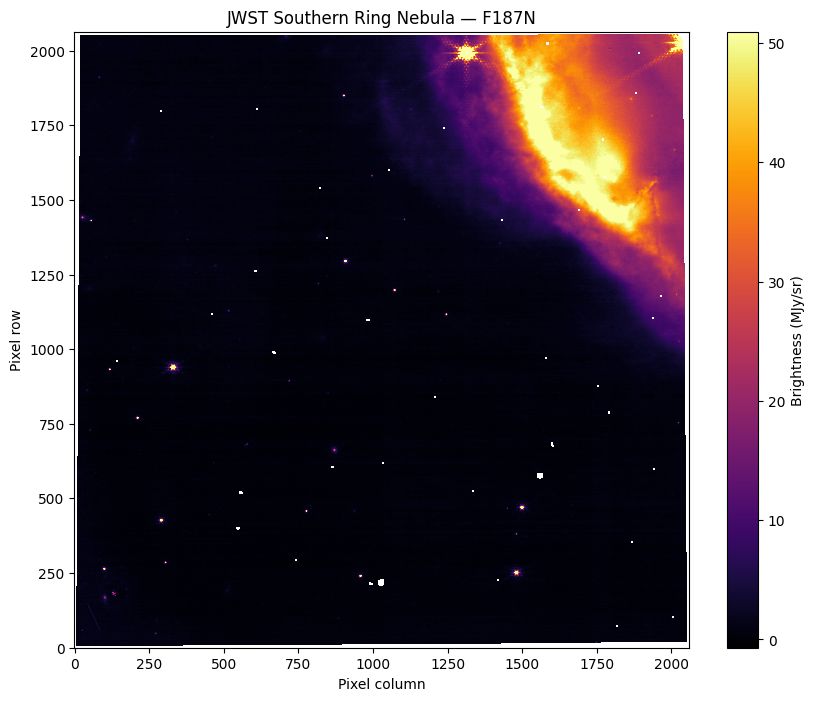

In [18]:
plt.figure(figsize=(10, 8))

plt.imshow(
    science,
    origin = "lower",
    cmap = "inferno",
    vmin = np.nanpercentile(science, 1),
    vmax = np.nanpercentile(science, 99)
)

plt.colorbar(label=f"Brightness ({units})")
plt.title("JWST Southern Ring Nebula — F187N")
plt.xlabel("Pixel column")
plt.ylabel("Pixel row")
plt.show()

In [19]:
with fits.open(file_path) as hdul:
    header = hdul["SCI"].header

    for key in [
        "TELESCOP",
        "INSTRUME",
        "FILTER",
        "TARGNAME",
        "RA",
        "DEC",
        "CRVAL1",
        "CRVAL2",
        "BUNIT"
    ]:
        print(f"{key}: {header.get(key, 'Not available')}")

TELESCOP: Not available
INSTRUME: Not available
FILTER: Not available
TARGNAME: Not available
RA: Not available
DEC: Not available
CRVAL1: 151.7423727963139
CRVAL2: -40.44148161181194
BUNIT: MJy/sr


In [20]:
with fits.open(file_path) as hdul:
    print("PRIMARY HEADER")
    print("Instrument:", hdul[0].header.get("INSTRUME"))
    print("Target:", hdul[0].header.get("TARGNAME"))

    print("\nSCIENCE HEADER")
    print("Instrument:", hdul["SCI"].header.get("INSTRUME"))
    print("Filter:", hdul["SCI"].header.get("FILTER"))
    print("Units:", hdul["SCI"].header.get("BUNIT"))

PRIMARY HEADER
Instrument: NIRCAM
Target: NGC 3132

SCIENCE HEADER
Instrument: None
Filter: None
Units: MJy/sr


In [21]:
with fits.open(file_path) as hdul:
    for i, hdu in enumerate(hdul):
        print(f"\n--- HDU {i}: {hdu.name} ---")

        for key in [
            "INSTRUME",
            "TARGNAME",
            "FILTER",
            "FILTER2",
            "CHANNEL",
            "DETECTOR",
            "PUPIL",
            "CRVAL1",
            "CRVAL2"
        ]:
            value = hdu.header.get(key)
            if value is not None:
                print(f"{key}: {value}")


--- HDU 0: PRIMARY ---
INSTRUME: NIRCAM
TARGNAME: NGC 3132
FILTER: F187N
CHANNEL: SHORT
DETECTOR: NRCB4
PUPIL: CLEAR

--- HDU 1: SCI ---
CRVAL1: 151.7423727963139
CRVAL2: -40.44148161181194

--- HDU 2: ERR ---

--- HDU 3: CON ---

--- HDU 4: WHT ---

--- HDU 5: VAR_POISSON ---

--- HDU 6: VAR_RNOISE ---

--- HDU 7: VAR_FLAT ---

--- HDU 8: ASDF ---


In [22]:
# Find the brightest pixel
brightest_index = np.nanargmax(science)

brightest_y, brightest_x = np.unravel_index(
    brightest_index,
    science.shape
) 

print("Brightest Pixel column: ", brightest_x)
print("Brightest Pixel row: ", brightest_y)
print("Brigtest Pixel value: ", science[brightest_y, brightest_x])
print("Image centre:", science.shape[1] // 2, science.shape[0] // 2)

Brightest Pixel column:  1312
Brightest Pixel row:  1993
Brigtest Pixel value:  35046.04
Image centre: 1029 1032


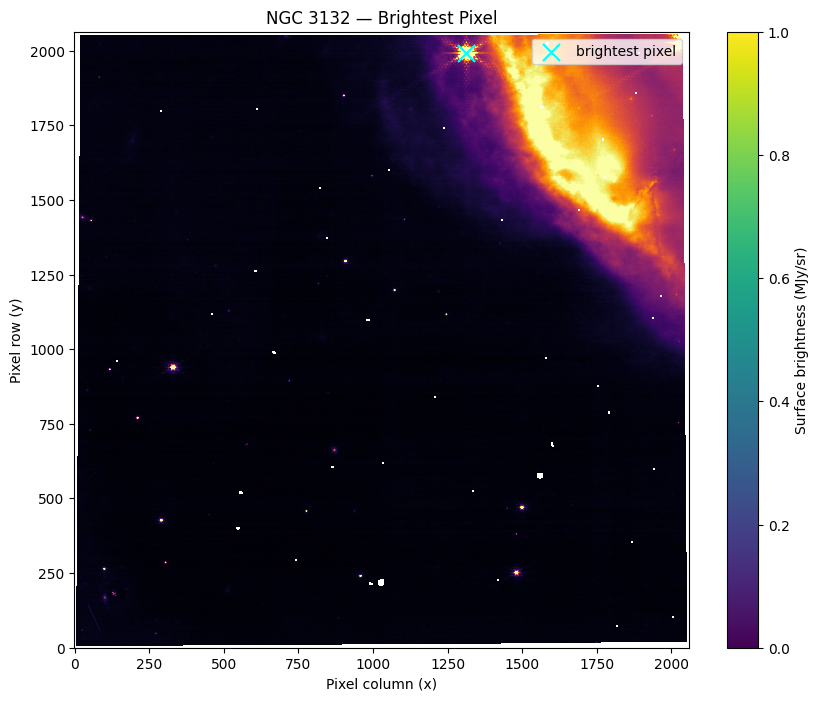

In [23]:
# Let's mark the brightest pixel on your image
plt.figure(figsize=(10, 8))

plt.imshow(
    science,
    origin = "lower",
    cmap = "inferno",
    vmin = np.nanpercentile(science, 1),
    vmax = np.nanpercentile(science, 99)
)

plt.scatter(
    brightest_x,
    brightest_y,
    color="cyan",
    marker="x",
    s=150,
    label="brightest pixel"
)

plt.colorbar(label=f"Surface brightness ({units})")
plt.xlabel("Pixel column (x)")
plt.ylabel("Pixel row (y)")
plt.title("NGC 3132 — Brightest Pixel")
plt.legend()
plt.show()

In [24]:
f187n_files = product_df[
    product_df["productFilename"].str.endswith("i2d.fits", na=False)
    & (product_df["filters"] == "F187N")
]

print("F187N FITS images:", len(f187n_files))

display(
    f187n_files[
        ["productFilename", "parent_obsid", "filters", "size"]
    ].head(30)
)


F187N FITS images: 33


,productFilename,parent_obsid,filters,size
26,jw02733001001_02103_00008_nrcb4_i2d.fits,87602522,F187N,119044800
58,jw02733001001_02103_00006_nrcb4_i2d.fits,87602522,F187N,119044800
90,jw02733001001_02103_00002_nrcb3_i2d.fits,87602522,F187N,118702080
106,jw02733001001_02103_00004_nrcb2_i2d.fits,87602522,F187N,118702080
202,jw02733001001_02103_00005_nrcb1_i2d.fits,87602522,F187N,118520640
484,jw02733001001_02103_00006_nrcb3_i2d.fits,87602522,F187N,118702080
596,jw02733001001_02103_00003_nrcb2_i2d.fits,87602522,F187N,118702080
612,jw02733001001_02103_00007_nrcb4_i2d.fits,87602522,F187N,119044800
644,jw02733001001_02103_00005_nrcb4_i2d.fits,87602522,F187N,119044800
660,jw02733001001_02103_00004_nrcb3_i2d.fits,87602522,F187N,118702080


In [25]:
from astropy.io import fits
from pathlib import Path
import pandas as pd

rows = []

for _, row in f187n_files.iterrows():
    name = row["productFilename"]

    # Check the file only if it has already been downloaded
    matches = list(Path("./jwst_data").rglob(name))

    if not matches:
        continue

    with fits.open(matches[0]) as hdul:
        h = hdul[1].header

        rows.append({
            "filename": name,
            "width": h.get("NAXIS1"),
            "height": h.get("NAXIS2"),
            "RA": h.get("CRVAL1"),
            "Dec": h.get("CRVAL2")
        })

footprints = pd.DataFrame(rows)
display(footprints)

,filename,width,height,RA,Dec
0,jw02733001001_02103_00008_nrcb4_i2d.fits,2058,2064,151.742373,-40.441482


In [26]:
obs_df = observations.to_pandas()

display(
    obs_df[
        obs_df["calib_level"] == 3
    ][
        [
            c for c in [
                "obs_collection",
                "obs_id",
                "target_name",
                "instrument_name",
                "filters",
                "calib_level"
            ]
            if c in obs_df.columns
        ]
    ]
)

,obs_collection,obs_id,target_name,instrument_name,filters,calib_level
0,OPO,STSCI_PR_2022-059,Southern Ring Nebula | NGC 3132,NaN,NaN,3
1,OPO,STSCI_PR_2022-033,NGC 3132 | Southern Ring Nebula | Eight-Burst ...,NaN,NaN,3
2,JWST,jw02733-o002_t001_miri_f1130w,NGC-3132,MIRI/IMAGE,F1130W,3
3,JWST,jw02733-o002_t001_miri_f770w,NGC-3132,MIRI/IMAGE,F770W,3
4,JWST,jw02733-o002_t001_miri_f1800w,NGC-3132,MIRI/IMAGE,F1800W,3
5,JWST,jw02733-o002_t001_miri_f1280w,NGC-3132,MIRI/IMAGE,F1280W,3
6,JWST,jw02733-o001_t001_nircam_clear-f187n,NGC-3132,NIRCAM/IMAGE,F187N,3
7,JWST,jw02733-o001_t001_nircam_clear-f090w,NGC-3132,NIRCAM/IMAGE,F090W,3
8,JWST,jw02733-o001_t001_nircam_clear-f356w,NGC-3132,NIRCAM/IMAGE,F356W,3
9,JWST,jw02733-o001_t001_nircam_clear-f212n,NGC-3132,NIRCAM/IMAGE,F212N,3
